In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

In [2]:
# Configure matplotlib to output both SVG (vector)
%config InlineBackend.figure_formats = ['svg']

#### Building the dataset
A dictionary-based dataset will be constructed using the .dat files output from the simulation. Important things to consider for users: the algorithm relies on .dat files following a specific naming convention in `obs_K_{k}_r0_{r0}_seed_{seed}.dat`.

The initial dictionary can be accessed using the folder name key e.g.:

`dat_files_dict['fd_push_full_rod_dats']`

A specific data set can be retrieved using:

`dat_files_dict['fd_push_full_rod_dats'][(k,r0,seed)]`

At any time, use `.keys()` to identify the available data fields at any level in the dictionary. All dictionaries follow a similar organisation.

In [3]:
#### READ SIMULATION OUTPUTS AND APPENDS THEM TO A DICTIONARY OF DATAFRAMES
INPUT_FOLDER = 'fextensions_results_bundles'

import re

def extract_parameters_from_filename(filename):
    """
    Extract K, r0, and seed from filename.
    Adjust the regex pattern to match your naming convention.
    
    Common patterns might be:
    - K_<value>_r0_<value>_seed_<value>.dat
    - output_K<value>_r0<value>_seed<value>.dat
    """
    # Try to extract K, r0, and seed using regex
    # Adjust this pattern based on your actual naming convention
    pattern = r'K[_]?(\d+(?:\.\d+)?)[_]?.*r0[_]?(\d+(?:\.\d+)?)[_]?.*seed[_]?(\d+)'
    
    match = re.search(pattern, filename, re.IGNORECASE)
    if match:
        K = float(match.group(1))
        r0 = float(match.group(2))
        seed = int(match.group(3))
        return K, r0, seed
    
    # If pattern doesn't match, return None
    return None

# Dictionary to store data from each subfolder
dat_files_dict = {}

# Iterate through subfolders using scandir
for subfolder_entry in os.scandir(INPUT_FOLDER):
    if subfolder_entry.is_dir():
        subfolder_name = subfolder_entry.name
        dat_files_dict[subfolder_name] = {}
        
        # Iterate through files in the subfolder using scandir
        for file_entry in os.scandir(subfolder_entry.path):
            if file_entry.is_file() and file_entry.name.endswith('.dat'):
                try:
                    # Extract parameters from filename
                    params = extract_parameters_from_filename(file_entry.name)
                    
                    if params:
                        K, r0, seed = params
                        
                        # Read the .dat file
                        data = pd.read_csv(file_entry.path, sep='\s+', header=None)
                        
                        # Store with (K, r0, seed) as key
                        dat_files_dict[subfolder_name][(K, r0, seed)] = {
                            'filename': file_entry.name,
                            'data': data,
                            'K': K,
                            'r0': r0,
                            'seed': seed
                        }
                        #print(f"Loaded: {subfolder_name}/{file_entry.name} -> K={K}, r0={r0}, seed={seed}")
                    else:
                        print(f"Warning: Could not extract parameters from {file_entry.name}")
                    
                except Exception as e:
                    print(f"Error reading {file_entry.path}: {e}")
        
        # Remove empty subfolder entries
        if len(dat_files_dict[subfolder_name]) == 0:
            del dat_files_dict[subfolder_name]

# Summary
print(f"\n{'='*60}")
print(f"Summary: Found {len(dat_files_dict)} subfolders with .dat files")
print(f"{'='*60}")
for subfolder, files in dat_files_dict.items():
    print(f"{subfolder}: {len(files)} file(s)")
    # Show example parameters
    if files:
        example_key = list(files.keys())[0]
        print(f"  Example access: dat_files_dict['{subfolder}'][{example_key}]")
print(f"{'='*60}")


Summary: Found 4 subfolders with .dat files
fd_4hb_mid_dats: 210 file(s)
  Example access: dat_files_dict['fd_4hb_mid_dats'][(25.0, 10.0, 1)]
fd_4hb_mid_staple_trials2_dats: 210 file(s)
  Example access: dat_files_dict['fd_4hb_mid_staple_trials2_dats'][(25.0, 10.0, 1)]
fd_6hb_mid_dats: 210 file(s)
  Example access: dat_files_dict['fd_6hb_mid_dats'][(25.0, 10.0, 1)]
fd_6hb_mid_staple_trials1_dats: 210 file(s)
  Example access: dat_files_dict['fd_6hb_mid_staple_trials1_dats'][(25.0, 10.0, 1)]


In [4]:
#### TESTING OUT DICTIONARY CONTENTS AND ACCESSIBILITY
print(dat_files_dict.keys())
test = dat_files_dict['fd_4hb_mid_dats'][(25, 10, 1)]
print(test.keys())

dict_keys(['fd_4hb_mid_dats', 'fd_4hb_mid_staple_trials2_dats', 'fd_6hb_mid_dats', 'fd_6hb_mid_staple_trials1_dats'])
dict_keys(['filename', 'data', 'K', 'r0', 'seed'])


#### Calculating steady state regions via manual cutoff

In [5]:
# NOTE: step values in these bundle datasets are O(1e4), not O(1e6)
CUTOFF = 2.0e4  # 25,000
COL_STEP = 0

# Create new dictionary for steady-state filtered data
ss_dat_files_dict = {}
empty_after_filter = 0
total_datasets = 0

# Iterate through all subfolders
for subfolder_name, files_dict in dat_files_dict.items():
    ss_dat_files_dict[subfolder_name] = {}

    # Iterate through all (K, r0, seed) combinations
    for (K, r0, seed), file_info in files_dict.items():
        total_datasets += 1
        df = file_info['data']

        # Apply cutoff filter (first column is simulation step)
        df_filtered = df[df.iloc[:, COL_STEP] >= CUTOFF].reset_index(drop=True)

        if len(df_filtered) == 0:
            empty_after_filter += 1

        # Store filtered data with same structure
        ss_dat_files_dict[subfolder_name][(K, r0, seed)] = {
            'filename': file_info['filename'],
            'data': df_filtered,
            'K': K,
            'r0': r0,
            'seed': seed
        }

# Summary
print(f"\n{'='*60}")
print("Cutoff filtering complete!")
print(f"Applied cutoff: step >= {CUTOFF}")
print(f"Processed {total_datasets} datasets")
print(f"Empty after cutoff: {empty_after_filter}")
if empty_after_filter == total_datasets and total_datasets > 0:
    print("Warning: all datasets are empty after filtering. Lower CUTOFF.")
print(f"{'='*60}")


Cutoff filtering complete!
Applied cutoff: step >= 20000.0
Processed 840 datasets
Empty after cutoff: 0


#### Computing statistics for each simulation

In [6]:
# Dictionary to store statistics for each simulation
stats_dict = {}
processed_count = 0
empty_count = 0

# Column indices (adjust based on your .dat file structure)
# Assuming columns are: [step, dist, force_mag, hbond]
COL_STEP = 0
COL_DIST = 1
COL_FORCE_MAG = 2
COL_HBOND = 3

# Iterate through all subfolders
for subfolder_name, files_dict in ss_dat_files_dict.items():
    stats_dict[subfolder_name] = {}
    
    # Iterate through all (K, r0, seed) combinations
    for (K, r0, seed), file_info in files_dict.items():
        df = file_info['data']
        
        if len(df) == 0:
            empty_count += 1
            continue
        
        # Extract columns as numpy arrays
        dist = df.iloc[:, COL_DIST].to_numpy()
        force_mag = df.iloc[:, COL_FORCE_MAG].to_numpy()
        hbond = df.iloc[:, COL_HBOND].to_numpy()
        
        # Calculate signed force: +|F| if dist > r0, -|F| if dist < r0
        signed_force = np.sign(dist - r0) * force_mag
        
        # Compute statistics
        stats_dict[subfolder_name][(K, r0, seed)] = {
            'K': K,
            'r0': r0,
            'seed': seed,
            'filename': file_info['filename'],
            
            # Signed force statistics
            'F_mean': signed_force.mean(),
            'F_std': signed_force.std(ddof=0),
            
            # Force magnitude statistics
            'force_mag_mean': force_mag.mean(),
            'force_mag_std': force_mag.std(ddof=0),
            
            # Distance statistics
            'dist_mean': dist.mean(),
            'dist_std': dist.std(ddof=0),
            
            # Hydrogen bond statistics
            'hbond_mean': hbond.mean(),
            'hbond_std': hbond.std(ddof=0),
            
            # Additional info
            'n_samples': len(df)
        }
        processed_count += 1
        
        #print(f"Computed stats for {subfolder_name} (K={K}, r0={r0}, seed={seed}): {len(df)} samples")

# Summary
print(f"\n{'='*60}")
print(f"Statistics computation complete!")
print(f"Processed {processed_count} datasets")
print(f"Skipped {empty_count} empty datasets")
if processed_count == 0:
    print("All filtered datasets are empty. Try lowering CUTOFF in the previous cell.")
print(f"{'='*60}")


Statistics computation complete!
Processed 840 datasets
Skipped 0 empty datasets


In [7]:
#### SET GLOBAL RC PARAMS
plt.rcParams.update({
    "axes.linewidth": 1,
    "xtick.major.width": 1,
    "ytick.major.width": 1,
    "xtick.major.size": 4,
    "ytick.major.size": 4,
    "font.size": 9,
    "axes.labelsize": 9,
    "xtick.minor.width": 1,
    "ytick.minor.width": 1,
    "xtick.minor.size": 2,
    "ytick.minor.size": 2,
    "font.sans-serif": ["Arial"]
})

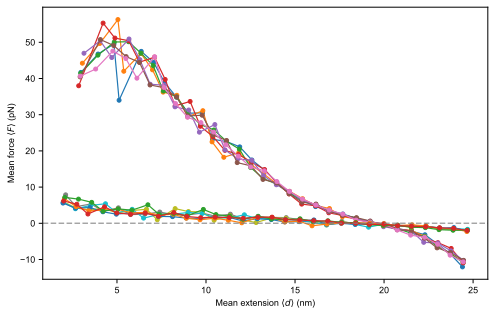

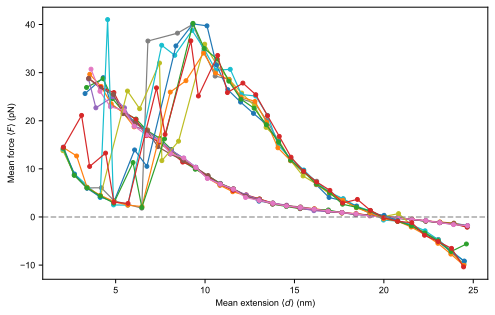

In [8]:
from collections import defaultdict
import numpy as np

# Unit conversion factors
DIST_CONVERSION = 0.8   # to nm
FORCE_CONVERSION = 48.6 # to pN

def _normalize_group_keys(group_keys):
    if group_keys is None:
        return None
    if isinstance(group_keys, str):
        return [group_keys]
    return list(group_keys)

def plot_force_extension(stats_dict, group_keys=None, figsize=(7, 4.5), show_legend=False):
    grouped = defaultdict(list)
    selected_groups = _normalize_group_keys(group_keys)

    for subfolder_name, files_dict in stats_dict.items():
        if selected_groups is not None and subfolder_name not in selected_groups:
            continue

        for (K, r0, seed), stats in files_dict.items():
            grouped[(subfolder_name, K, seed)].append((stats['dist_mean'], stats['F_mean']))

    if not grouped:
        print(f"No trajectories found for groups: {selected_groups}")
        return

    fig, ax = plt.subplots(figsize=figsize)

    for (subfolder_name, K, seed), points in grouped.items():
        points = np.array(sorted(points, key=lambda p: p[0]))
        x = DIST_CONVERSION * points[:, 0]
        y = FORCE_CONVERSION * points[:, 1]
        ax.plot(x, y, marker='o', linewidth=1.2, markersize=4,
                label=f"{subfolder_name}, K={K}, seed={seed}")

    ax.axhline(0, color='gray', linestyle='dashed', alpha=0.7)
    ax.set_xlabel(r"Mean extension $\langle d \rangle$ (nm)")
    ax.set_ylabel(r"Mean force $\langle F \rangle$ (pN)")

    if show_legend:
        ax.legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc='upper left')

    plt.tight_layout()
    plt.show()

# Combined raw trajectories in a single plot (no duplicate matching)
plot_force_extension(
    stats_dict,
    group_keys=['fd_4hb_mid_dats', 'fd_4hb_mid_staple_trials2_dats'],
    show_legend=False,
)

plot_force_extension(
    stats_dict,
    group_keys=['fd_6hb_mid_dats', 'fd_6hb_mid_staple_trials1_dats'],
    show_legend=False,
)

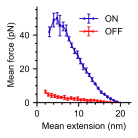


fd_4hb_mid_dats
  K=25.0: area under positive mean trajectory = 384.4305 pN*nm (10^-21 J) -> 55.330796 kcal/mol

fd_4hb_mid_staple_trials2_dats
  K=25.0: area under positive mean trajectory = 34.4820 pN*nm (10^-21 J) -> 4.962975 kcal/mol


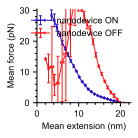


fd_6hb_mid_dats
  K=25.0: area under positive mean trajectory = 146.3535 pN*nm (10^-21 J) -> 21.064543 kcal/mol

fd_6hb_mid_staple_trials1_dats
  K=25.0: area under positive mean trajectory = 275.5885 pN*nm (10^-21 J) -> 39.665244 kcal/mol


In [ ]:
#### Aggregate means/error bars across seeds (single dataset layout)
from collections import defaultdict
import numpy as np

AVOGADRO = 6.022e23  # molecules per mole

def _normalize_group_keys(group_keys):
    if group_keys is None:
        return []
    if isinstance(group_keys, str):
        return [group_keys]
    return list(group_keys)

def aggregate_by_K_r0(stats_dict, group_keys=None):
    """Aggregate mean force-extension by (K, r0) across seeds for one or more groups."""
    if not stats_dict:
        return {}

    selected_groups = _normalize_group_keys(group_keys)
    if not selected_groups:
        selected_groups = list(stats_dict.keys())

    aggregated_by_group = {}

    for group_key in selected_groups:
        files_dict = stats_dict.get(group_key, {})
        grouped = defaultdict(list)

        for (K, r0, seed), stats in files_dict.items():
            grouped[(K, r0)].append(stats)

        aggregated = defaultdict(list)
        for (K, r0), entries in grouped.items():
            dist_vals = np.array([e['dist_mean'] for e in entries])
            force_vals = np.array([e['F_mean'] for e in entries])
            ddof = 1 if len(entries) > 1 else 0

            aggregated[K].append({
                'K': K,
                'r0': r0,
                'dist_mean': dist_vals.mean(),
                'F_mean': force_vals.mean(),
                'dist_err': dist_vals.std(ddof=ddof),
                'F_err': force_vals.std(ddof=ddof),
                'n': len(entries),
            })

        for K in aggregated:
            aggregated[K] = sorted(aggregated[K], key=lambda x: x['dist_mean'])

        aggregated_by_group[group_key] = dict(aggregated)

    return aggregated_by_group

def plot_aggregated_curves_by_K(
    stats_dict,
    group_keys=None,
    group_labels=None,
    group_colors=None,
    figsize=(2, 2),
    xlim=None,
    ylim=None,
):
    aggregated_by_group = aggregate_by_K_r0(stats_dict, group_keys=group_keys)
    if not aggregated_by_group:
        print("No aggregated data available.")
        return {}, {}

    nonempty_groups = {g: d for g, d in aggregated_by_group.items() if d}
    if not nonempty_groups:
        print(f"No aggregated data available for groups: {_normalize_group_keys(group_keys)}")
        return aggregated_by_group, {}

    fig, ax = plt.subplots(figsize=figsize)

    all_x = [
        DIST_CONVERSION * point['dist_mean']
        for group_data in nonempty_groups.values()
        for points in group_data.values()
        for point in points
    ]
    if all_x:
        xmin = min(all_x) if xlim is None or xlim[0] is None else xlim[0]
        xmax = max(all_x) if xlim is None or xlim[1] is None else xlim[1]
        ax.hlines(0, xmin=xmin, xmax=xmax, colors='gray', linestyles='dashed', alpha=0.7)

    group_names = list(nonempty_groups.keys())
    n_groups = len(group_names)

    if group_labels is not None and len(group_labels) != n_groups:
        raise ValueError("group_labels must have the same length as selected groups")
    if group_colors is not None and len(group_colors) != n_groups:
        raise ValueError("group_colors must have the same length as selected groups")

    cmap = plt.get_cmap('tab10')
    area_by_group = {}

    for gi, group_name in enumerate(group_names):
        group_label = group_labels[gi] if group_labels is not None else group_name
        group_color = group_colors[gi] if group_colors is not None else cmap(gi % 10)
        group_data = nonempty_groups[group_name]
        area_by_group[group_name] = {}

        for K in sorted(group_data.keys()):
            points = group_data[K]
            x = np.array([DIST_CONVERSION * p['dist_mean'] for p in points])
            y = np.array([FORCE_CONVERSION * p['F_mean'] for p in points])
            xerr = np.array([DIST_CONVERSION * p['dist_err'] for p in points])
            yerr = np.array([FORCE_CONVERSION * p['F_err'] for p in points])

            ax.errorbar(
                x, y, xerr=xerr, yerr=yerr,
                linestyle='-', color=group_color,
                marker=None, markersize=3, linewidth=1, capsize=1.5,
                alpha=0.95,
                label=f"{group_label}"
            )

            area = np.trapezoid(np.maximum(y, 0.0), x) if len(x) > 1 else float('nan')
            area_by_group[group_name][K] = area

    ax.set_xlabel(r"Mean extension (nm)")
    ax.set_ylabel(r"Mean force (pN)")
    if xlim is not None:
        ax.set_xlim(*xlim)
    if ylim is not None:
        ax.set_ylim(*ylim)
    ax.legend(frameon=False, ncol=1)
    ax.minorticks_on()
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    plt.tight_layout()
    plt.show()

    for group_name, areas in area_by_group.items():
        print(f"\n{group_name}")
        for K, area in areas.items():
            kcalpermol = area * 1e-21 * AVOGADRO / 4184
            print(f"  K={K}: area under positive mean trajectory = {area:.4f} pN*nm (10^-21 J) -> {kcalpermol:.6f} kcal/mol")

    return aggregated_by_group, area_by_group

# Plot both groups together in one mean/errorbar figure
combined_aggregated_data, combined_area_by_group = plot_aggregated_curves_by_K(
    stats_dict,
    group_keys=['fd_4hb_mid_dats', 'fd_4hb_mid_staple_trials2_dats'],
    group_labels=['ON', 'OFF'],
    group_colors=["#2308bd", "#ff0a0a"],
    xlim=(0, 22.5),
    ylim=(0, 56.5),
)

combined_aggregated_data, combined_area_by_group = plot_aggregated_curves_by_K(
    stats_dict,
    group_keys=['fd_6hb_mid_dats', 'fd_6hb_mid_staple_trials1_dats'],
    group_labels=['nanodevice ON', 'nanodevice OFF'],
    group_colors=["#2308bd", "#ff0a0a"],
    xlim=(0, 22.5),
    ylim=(0, None),
)

In [10]:
#### Work-only utility functions (no plotting)
from collections import defaultdict
import numpy as np


def get_trajectory_work_list(
    stats_dict,
    group_key,
    dist_conversion=0.8,
    force_conversion=48.6,
    work_conversion=1.0,
    positive_force_only=True,
):
    """
    Compute work per trajectory for one group.

    Returns:
        list[float]: one work value per trajectory, in units set by work_conversion.
    """
    files_dict = stats_dict.get(group_key, {})
    by_k_seed = defaultdict(list)

    for (K, r0, seed), stats in files_dict.items():
        by_k_seed[(K, seed)].append((stats['dist_mean'], stats['F_mean']))

    work_values = []
    for (_, _), points in by_k_seed.items():
        points = sorted(points, key=lambda p: p[0])
        x = dist_conversion * np.array([p[0] for p in points])
        y = force_conversion * np.array([p[1] for p in points])

        if positive_force_only:
            y = np.maximum(y, 0.0)

        work = np.trapezoid(y, x) if len(x) > 1 else np.nan
        work = work * work_conversion

        if np.isfinite(work):
            work_values.append(float(work))

    return work_values


def get_work_lists_by_group(
    stats_dict,
    group_keys,
    dist_conversion=0.8,
    force_conversion=48.6,
    work_conversion=1.0,
    positive_force_only=True,
):
    """
    Compute work lists for multiple groups.

    Returns:
        dict[str, list[float]]: group -> per-trajectory work list.
    """
    return {
        group_key: get_trajectory_work_list(
            stats_dict=stats_dict,
            group_key=group_key,
            dist_conversion=dist_conversion,
            force_conversion=force_conversion,
            work_conversion=work_conversion,
            positive_force_only=positive_force_only,
        )
        for group_key in group_keys
    }


# Example: kcal/mol conversion from pN*nm
PN_NM_TO_KCAL_PER_MOL = 1e-21 * 6.022e23 / 4184

work_lists_kcal = get_work_lists_by_group(
    stats_dict,
    group_keys=['fd_4hb_mid_dats', 'fd_4hb_mid_staple_trials2_dats'],
    dist_conversion=0.8,
    force_conversion=48.6,
    work_conversion=PN_NM_TO_KCAL_PER_MOL,
    positive_force_only=True,
)

for name, values in work_lists_kcal.items():
    print(name, len(values), 'trajectories')

work_lists_kcal


fd_4hb_mid_dats 7 trajectories
fd_4hb_mid_staple_trials2_dats 7 trajectories


{'fd_4hb_mid_dats': [55.16693094108818,
  55.26432541482858,
  56.01956834859316,
  57.56047865092074,
  54.06759477946932,
  54.92251155197222,
  54.194359216461635],
 'fd_4hb_mid_staple_trials2_dats': [5.490445336876333,
  5.033432167694548,
  5.160903832494345,
  4.160666365122696,
  4.243829984768924,
  6.143177218471989,
  4.792024492269641]}

50.29378739329548 49.419304797365136 51.307751470896136


(-5.7039755317686005, 68.39588010021134)

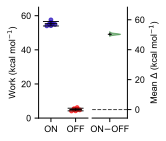

In [11]:
fig, ax = plt.subplots(
    1, 2, figsize=(1.6, 2),
    gridspec_kw={'width_ratios': [1.4, 1], 'wspace': 0.1}
)
group_keys = ['fd_4hb_mid_dats', 'fd_4hb_mid_staple_trials2_dats']
group_labels = ['ON', 'OFF']

# Color controls
scatter_colors = ['#2308bd', '#ff0a0a']
errorbar_colors = ['black', 'black']
mean_line_colors = ['#2308bd', '#ff0a0a']
right_raw_color = "#086e0f"
right_zero_color = '#444444'
right_upper_headroom = 1.30
right_n_bootstrap = 20000
right_rng_seed = 42


def auto_bin_points(y, bins='auto', min_bins=3, max_bins=12):
    """
    Lightweight scaffold for automatic y-binning.

    Returns:
        bin_idx: array of bin id per point (0-based)
        bin_edges: array of bin edges
        bin_to_indices: dict {bin_id: np.ndarray(point_indices)}
    """
    y = np.asarray(y, dtype=float)
    n = len(y)

    if n == 0:
        return np.array([], dtype=int), np.array([0.0, 1.0]), {}
    if n == 1:
        return np.array([0], dtype=int), np.array([y[0] - 0.5, y[0] + 0.5]), {0: np.array([0], dtype=int)}

    # Initial automatic edges from numpy strategy.
    edges = np.histogram_bin_edges(y, bins=bins)
    n_bins = len(edges) - 1

    # Clamp bin count for stability/readability.
    if n_bins < min_bins or n_bins > max_bins:
        n_bins = int(np.clip(n_bins, min_bins, max_bins))
        edges = np.linspace(y.min(), y.max(), n_bins + 1)

    bin_idx = np.digitize(y, edges[1:-1], right=False)
    bin_to_indices = {b: np.where(bin_idx == b)[0] for b in range(n_bins)}

    return bin_idx, edges, bin_to_indices


def jitter_points(y, bin_to_indices, jitter_range=0.1):
    y = np.asarray(y, dtype=float)
    x_offsets = np.zeros(len(y), dtype=float)
    if len(y) == 0 or len(bin_to_indices) == 0:
        return x_offsets

    largest_bin = max(bin_to_indices, key=lambda b: len(bin_to_indices[b]))
    largest_len = len(bin_to_indices[largest_bin])

    for b, idx in bin_to_indices.items():
        count = len(idx)
        if count == 0:
            continue
        if count == 1:
            x_offsets[idx[0]] = 0.0
            continue

        current_is_odd = (count % 2 == 1)
        largest_is_odd = (largest_len % 2 == 1)

        if largest_is_odd and current_is_odd:
            denom = largest_len
            candidate_count = largest_len
        elif largest_is_odd and not current_is_odd:
            denom = largest_len + 1
            candidate_count = largest_len + 1
        elif (not largest_is_odd) and (not current_is_odd):
            denom = largest_len
            candidate_count = largest_len
        else:
            denom = largest_len + 1
            candidate_count = largest_len + 1

        step = jitter_range / max(denom, 1)
        candidates = (np.arange(candidate_count) - (candidate_count - 1) / 2.0) * step

        # Assign offsets closest to center first, then map in y-order for determinism.
        chosen = candidates[np.argsort(np.abs(candidates))[:count]]
        chosen = np.sort(chosen)
        idx_sorted = idx[np.argsort(y[idx])]
        x_offsets[idx_sorted] = chosen

    return x_offsets


group_values = {}
for i, group_key in enumerate(group_keys):
    values = np.asarray(work_lists_kcal.get(group_key, []), dtype=float)
    group_values[group_key] = values

    bin_idx, bin_edges, bin_to_indices = auto_bin_points(values, bins='fd', min_bins=3, max_bins=10)
    x_offsets = jitter_points(values, bin_to_indices, jitter_range=0.50)

    x = np.full(len(values), i, dtype=float) + x_offsets
    ax[0].scatter(x, values, label=group_labels[i], alpha=0.7, color=scatter_colors[i],
                  s=15)

    mean_val = values.mean() if len(values) > 0 else np.nan
    std_val = values.std(ddof=2) if len(values) > 2 else (values.std(ddof=1) if len(values) > 1 else 0.0)

    ax[0].errorbar(
        i, mean_val, yerr=std_val,
        marker=None,
        color=errorbar_colors[i], capsize=8, fmt='none',
        elinewidth=1, alpha=0.9
    )

    mean_range = 0.25
    ax[0].hlines(mean_val, i - mean_range, i + mean_range, color='black', linewidth=1)

# Left panel format
ax[0].set_xlim(-0.5, len(group_keys) - 0.5)
ax[0].set_ylim(0, 65)
ax[0].set_xticks(range(len(group_keys)))
ax[0].set_xticklabels(group_labels)
ax[0].set_yscale('linear')
ax[0].set_ylabel("Work (kcal mol$^{-1}$)")
ax[0].spines['top'].set_visible(False)
ax[0].spines['right'].set_visible(False)

# Right panel: bootstrap distribution of mean difference (ON - OFF),
# with y=0 aligned to OFF mean in left panel.
on_vals = group_values[group_keys[0]]
off_vals = group_values[group_keys[1]]
off_mean = off_vals.mean() if len(off_vals) > 0 else 0.0

if len(on_vals) > 0 and len(off_vals) > 0:
    rng_right = np.random.default_rng(right_rng_seed)
    boot_on = rng_right.choice(on_vals, size=(right_n_bootstrap, len(on_vals)), replace=True).mean(axis=1)
    boot_off = rng_right.choice(off_vals, size=(right_n_bootstrap, len(off_vals)), replace=True).mean(axis=1)
    plot_contrast = boot_on - boot_off
    obs_contrast = float(on_vals.mean() - off_vals.mean())
else:
    plot_contrast = np.array([0.0])
    obs_contrast = 0.0

vp = ax[1].violinplot(
    plot_contrast,
    positions=[0.0],
    widths=0.55,
    showmeans=False,
    showmedians=False,
    showextrema=False,
    bw_method=0.35,
    points=300,
    )
for body in vp['bodies']:
    body.set_facecolor(right_raw_color)
    body.set_edgecolor(right_raw_color)
    body.set_linewidth(1)
    body.set_alpha(0.45)
    verts = body.get_paths()[0].vertices
    verts[:, 0] = np.maximum(verts[:, 0], 0.0)  # keep right half only
#vp['cmedians'].set_color(right_raw_color)
#vp['cmedians'].set_linewidth(1.6)
median_contrast = float(np.median(plot_contrast))
ci_lo, ci_hi = np.percentile(plot_contrast, [2.5, 97.5])
print(median_contrast, ci_lo, ci_hi)

ax[1].axhline(0.0, color=right_zero_color, linestyle='--', linewidth=1)
ax[1].vlines(0.0, ci_lo, ci_hi, color='black', linewidth=1, zorder=5)
ax[1].hlines(median_contrast, -0.05, 0.05, color='black', linewidth=1, zorder=6)

ax[1].set_xlim(-0.45, 0.45)
ax[1].set_xticks([0.0])
ax[1].set_xticklabels(['ON$-$OFF'])
ax[1].set_ylabel('Mean $\\Delta$ (kcal mol$^{-1}$)')

# Put y-axis on the right side
ax[1].yaxis.set_label_position('right')
ax[1].yaxis.tick_right()
ax[1].spines['top'].set_visible(False)
ax[1].spines['left'].set_visible(False)

# Force visual alignment: ax[1] y=0 is at same pixel height as OFF mean on ax[0],
# with extra upper headroom so the half-violin does not look cut off.
y0_min, y0_max = ax[0].get_ylim()
f = (off_mean - y0_min) / (y0_max - y0_min) if y0_max > y0_min else 0.5
f = float(np.clip(f, 1e-6, 1 - 1e-6))

rmin = float(np.min(plot_contrast)) if len(plot_contrast) else -1.0
rmax = float(np.max(plot_contrast)) if len(plot_contrast) else 1.0
span = (rmax - rmin) if rmax > rmin else 1.0
pad = 0.12 * span
lower_req = rmin - pad
upper_req = rmax + pad

upper_target = upper_req * right_upper_headroom
upper_needed_for_lower = (1 - f) * (-lower_req) / f
upper_bound = max(upper_target, upper_needed_for_lower, 1e-6)
lower_bound = -(f / (1 - f)) * upper_bound
ax[1].set_ylim(lower_bound, upper_bound)


In [12]:
from itertools import combinations
from scipy.stats import pearsonr
import pandas as pd


def within_group_pairwise_pcc(
    stats_dict,
    group_key,
    value_key='F_mean',
):
    """Compute pairwise Pearson correlations between trajectories within one group."""
    files_dict = stats_dict.get(group_key, {})
    trajectories = {}

    for (K, r0, seed), stats in files_dict.items():
        trajectories.setdefault((K, seed), {})[r0] = stats[value_key]

    rows = []
    for (K1, seed1), (K2, seed2) in combinations(sorted(trajectories), 2):
        shared_r0 = sorted(set(trajectories[(K1, seed1)]) & set(trajectories[(K2, seed2)]))
        if len(shared_r0) < 2:
            continue

        vals1 = np.array([trajectories[(K1, seed1)][r0] for r0 in shared_r0], dtype=float)
        vals2 = np.array([trajectories[(K2, seed2)][r0] for r0 in shared_r0], dtype=float)
        r_val, p_val = pearsonr(vals1, vals2)

        rows.append({
            'traj_1_seed': seed1,
            'traj_2_seed': seed2,
            'n_shared_r0': len(shared_r0),
            'pearson_r': r_val,
            'p_value': p_val,
        })

    pairwise_df = pd.DataFrame(rows).sort_values(['traj_1_seed', 'traj_2_seed']).reset_index(drop=True)
    mean_pcc = pairwise_df['pearson_r'].mean() if not pairwise_df.empty else np.nan
    return mean_pcc, pairwise_df


on_mean_pcc, on_pairwise_pcc_df = within_group_pairwise_pcc(
    stats_dict,
    group_key='fd_4hb_mid_dats',
    value_key='F_mean',
)

off_mean_pcc, off_pairwise_pcc_df = within_group_pairwise_pcc(
    stats_dict,
    group_key='fd_4hb_mid_staple_trials2_dats',
    value_key='F_mean',
)

print('4HB within-state Pearson correlation summary')
print(f"ON mean pairwise PCC across 7 trajectories  = {on_mean_pcc:.4f}")
print(f"OFF mean pairwise PCC across 7 trajectories = {off_mean_pcc:.4f}")
print()
print(f"ON pair count  = {len(on_pairwise_pcc_df)}")
print(f"OFF pair count = {len(off_pairwise_pcc_df)}")

pd.DataFrame({
    'group': ['ON', 'OFF'],
    'mean_pairwise_pcc': [on_mean_pcc, off_mean_pcc],
    'n_trajectories': [7, 7],
    'n_pairs': [len(on_pairwise_pcc_df), len(off_pairwise_pcc_df)],
})

4HB within-state Pearson correlation summary
ON mean pairwise PCC across 7 trajectories  = 0.9905
OFF mean pairwise PCC across 7 trajectories = 0.9354

ON pair count  = 21
OFF pair count = 21


,group,mean_pairwise_pcc,n_trajectories,n_pairs
0,ON,0.990500,7,21
1,OFF,0.935351,7,21
